# Google play store data base 

In [ ]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Before cleaning


In [3]:
df = pd.read_csv("googleplaystore.csv")

In [4]:
df.head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


In [5]:
df.tail()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
10836,Sya9a Maroc - FR,FAMILY,4.5,38,53M,"5,000+",Free,0,Everyone,Education,"July 25, 2017",1.48,4.1 and up
10837,Fr. Mike Schmitz Audio Teachings,FAMILY,5.0,4,3.6M,100+,Free,0,Everyone,Education,"July 6, 2018",1.0,4.1 and up
10838,Parkinson Exercices FR,MEDICAL,NaN,3,9.5M,"1,000+",Free,0,Everyone,Medical,"January 20, 2017",1.0,2.2 and up
10839,The SCP Foundation DB fr nn5n,BOOKS_AND_REFERENCE,4.5,114,Varies with device,"1,000+",Free,0,Mature 17+,Books & Reference,"January 19, 2015",Varies with device,Varies with device
10840,iHoroscope - 2018 Daily Horoscope & Astrology,LIFESTYLE,4.5,398307,19M,"10,000,000+",Free,0,Everyone,Lifestyle,"July 25, 2018",Varies with device,Varies with device


In [6]:
df.sample(4)

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
8983,News: DW Español,NEWS_AND_MAGAZINES,4.3,25,6.3M,"1,000+",Free,0,Everyone,News & Magazines,"April 26, 2018",1.0,4.1 and up
2752,Walmart,SHOPPING,4.4,441473,Varies with device,"10,000,000+",Free,0,Everyone,Shopping,"July 30, 2018",Varies with device,Varies with device
9463,Sport Car Simulator,FAMILY,4.0,48731,68M,"5,000,000+",Free,0,Everyone,Simulation,"April 19, 2018",4.0.5,4.1 and up
10005,European War 6: 1804,FAMILY,4.2,1330,96M,"10,000+",Paid,$0.99,Teen,Strategy,"July 18, 2018",1.1.0,4.4 and up


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  object 
 1   Category        10841 non-null  object 
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  object 
 4   Size            10841 non-null  object 
 5   Installs        10841 non-null  object 
 6   Type            10840 non-null  object 
 7   Price           10841 non-null  object 
 8   Content Rating  10840 non-null  object 
 9   Genres          10841 non-null  object 
 10  Last Updated    10841 non-null  object 
 11  Current Ver     10833 non-null  object 
 12  Android Ver     10838 non-null  object 
dtypes: float64(1), object(12)
memory usage: 1.1+ MB


In [8]:
df.describe()

,Rating
count,9367.000000
mean,4.193338
std,0.537431
min,1.000000
25%,4.000000
50%,4.300000
75%,4.500000
max,19.000000


## Handling missing data 

In [22]:
df.dropna(subset= ["Rating"], inplace=True)

In [ ]:
df.fillna({'Type': df['Type'].mode()[0]}, inplace=True)

In [25]:
df.fillna({'Content Rating': df['Content Rating'].mode()[0]}, inplace=True)

In [26]:
df.fillna({'Current Ver': df['Current Ver'].mode()[0]}, inplace=True)

In [27]:
df.fillna({'Android Ver': df['Android Ver'].mode()[0]}, inplace=True)

Missing values are handled

## Handle Data type

### Fixing Rating

In [30]:
df = df[df['Rating'] <= 5]

In [ ]:
df['Rating'] = df['Rating'].fillna(df['Rating'].median())

In [34]:
print(df['Rating'].describe())

count    9366.000000
mean        4.191757
std         0.515219
min         1.000000
25%         4.000000
50%         4.300000
75%         4.500000
max         5.000000
Name: Rating, dtype: float64


### Fixing Size

In [ ]:
def convert_size(size):
    if 'M' in size:
        return float(size.replace('M', '')) * 1_000_000
    elif 'k' in size:
        return float(size.replace('k', '')) * 1_000
    else:
        return np.nan 


In [36]:
df['Size'] = df['Size'].apply(lambda x: convert_size(str(x)))


In [38]:
df['Size'] = df['Size'].fillna(df['Size'].median())

In [39]:
print(df['Size'].describe())

count    9.366000e+03
mean     2.139199e+07
std      2.156802e+07
min      8.500000e+03
25%      6.600000e+06
50%      1.400000e+07
75%      2.700000e+07
max      1.000000e+08
Name: Size, dtype: float64


### Fixing price

In [46]:
df['Price'] = df['Price'].apply(lambda x: float(str(x).replace('$', '')) if isinstance(x, str) and '$' in x else float(x))


### Fixing reviews

In [29]:
def convert_reviews(value):
    value = str(value)
    if 'M' in value:
        return int(float(value.replace('M', '')) * 1_000_000)
    return int(value)

df['Reviews'] = df['Reviews'].apply(lambda x: convert_reviews(x))

print(df['Reviews'].dtype)  


int64


### Fixing installs

In [47]:
df['Installs'] = df['Installs'].str.replace(',', '').str.replace('+', '').astype(int)

print(df[['App', 'Installs']].head())


                                                 App  Installs
0     Photo Editor & Candy Camera & Grid & ScrapBook     10000
1                                Coloring book moana    500000
2  U Launcher Lite – FREE Live Cool Themes, Hide ...   5000000
3                              Sketch - Draw & Paint  50000000
4              Pixel Draw - Number Art Coloring Book    100000


### Fixing android version

In [50]:
df['Android Ver'] = df['Android Ver'].fillna("Unknown")


df['Min Android Version'] = df['Android Ver'].apply(lambda x: x.split()[0] if x != "Unknown" else x)

print(df['Min Android Version'].value_counts())


Min Android Version
4.1       2062
Varies    1319
4.0.3     1242
4.0       1131
4.4        875
2.3        582
5.0        538
4.2        338
2.3.3      240
3.0        211
2.2        208
4.3        207
2.1        113
1.6         87
6.0         48
7.0         42
3.2         31
2.0         27
5.1         18
1.5         16
3.1          8
2.0.1        7
4.4W         6
8.0          5
7.1          3
1.0          2
Name: count, dtype: int64


#### Check for missing values

In [51]:
print(df.isnull().sum())

App                    0
Category               0
Rating                 0
Reviews                0
Size                   0
Installs               0
Type                   0
Price                  0
Content Rating         0
Genres                 0
Last Updated           0
Current Ver            0
Android Ver            0
Min Android Version    0
dtype: int64


#### prefect

##                                                   Outlier 

Text(0.5, 1.0, 'Reviews Outliers')

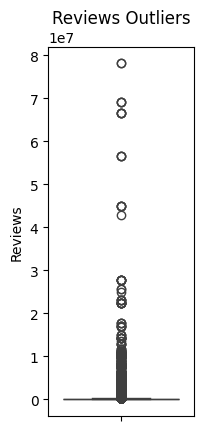

In [60]:

plt.subplot(1, 3, 1)
sns.boxplot(y=df['Reviews'])
plt.title('Reviews Outliers')

Text(0.5, 1.0, 'Size Outliers')

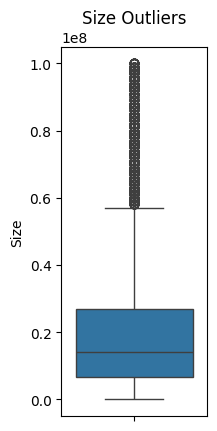

In [59]:
plt.subplot(1, 3, 2)
sns.boxplot(y=df['Size'])
plt.title('Size Outliers')


Text(0.5, 1.0, 'Price Outliers')

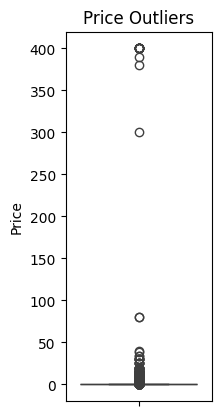

In [ ]:
plt.subplot(1, 3, 3)
sns.boxplot(y=df['Price'])
plt.title('Price Outliers')

In [62]:
df = df[df['Price'] < 300]  
df = df[df['Reviews'] < df['Reviews'].quantile(0.99)] 
df = df[df['Size'] < df['Size'].quantile(0.99)]

# Analytical Questions:

## 1.	What is the most expensive app on the Play Store?

In [68]:
df[df['Price'] == df['Price'].max()]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver,Min Android Version
5355,I am rich VIP,LIFESTYLE,3.8,411,2600000.0,10000,Paid,299.99,Everyone,Lifestyle,"July 21, 2018",1.1.1,4.3 and up,4.3


## 1.	Which genre has the highest number of apps?

In [70]:
df['Genres'].value_counts().head()

Genres
Tools            726
Entertainment    525
Education        467
Productivity     351
Medical          348
Name: count, dtype: int64

## 1.	What is the average size of free vs. paid apps?

In [71]:
df.groupby('Type')['Size'].mean()

Type
Free    2.042676e+07
Paid    1.928903e+07
Name: Size, dtype: float64

## 1.	What are the top 5 most expensive apps with a perfect rating (5)?

In [72]:
df[df['Rating'] == 5].sort_values(by='Price', ascending=False).head(5)

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver,Min Android Version
7477,USMLE Step 2 CK Flashcards,FAMILY,5.0,1,40000000.0,10,Paid,19.99,Everyone,Education,"May 26, 2014",2.47,2.2 and up,2.2
7204,TI-84 CE Graphing Calculator Manual TI 84,FAMILY,5.0,1,27000000.0,100,Paid,4.99,Everyone,Education,"March 28, 2018",1.5.2,4.1 and up,4.1
5482,meStudying: AP English Lit,FAMILY,5.0,1,655000.0,10,Paid,4.99,Everyone,Education,"August 31, 2013",1.3,2.0.1 and up,2.0.1
5246,Hey AJ! It's Bedtime!,FAMILY,5.0,1,63000000.0,10,Paid,4.99,Everyone,Education,"April 4, 2018",1.0.59,2.3 and up,2.3
5237,Hey AJ! It's Saturday!,BOOKS_AND_REFERENCE,5.0,12,50000000.0,100,Paid,3.99,Everyone,Books & Reference,"June 13, 2016",1.0.0,2.2 and up,2.2


## 5.	How many apps have received more than 50K reviews?

In [77]:
df[df['Reviews'] > 50_000].shape[0]


2626

## 1.	What is the average price of apps, grouped by genre and number of installs?

In [80]:
df.groupby(['Genres', 'Installs'])['Price'].mean().reset_index()


,Genres,Installs,Price
0,Action,10,0.000000
1,Action,50,1.990000
2,Action,100,1.370000
3,Action,1000,0.496667
4,Action,5000,0.000000
...,...,...,...
807,Word,100000,0.000000
808,Word,1000000,0.000000
809,Word,5000000,0.000000
810,Word,10000000,0.000000


## 1.	How many apps have a rating higher than 4.7, and what is their average price?

In [83]:
high_rating = df[df['Rating'] > 4.7]
print("High rating apps are:", high_rating.shape[0])
print("thier avg price:", high_rating['Price'].mean())

High rating apps are: 593
thier avg price: 0.45296795952782465


## What is Google's estimated revenue from apps with 5,000,000+ installs?
(Assuming Google takes a 30% cut from app sales


In [84]:
df['Revenue'] = df['Installs'] * df['Price'] * 0.30 
df[df['Installs'] >= 5_000_000]['Revenue'].sum()


np.float64(44910000.0)

## 1.	What are the maximum and minimum sizes of free vs. paid apps?

In [85]:
df.groupby('Type')['Size'].agg(['max', 'min'])

,max,min
Type,,
Free,95000000.0,8500.0
Paid,95000000.0,14000.0


## 1.	Is there a correlation between an app’s rating, number of reviews, size, and its price?

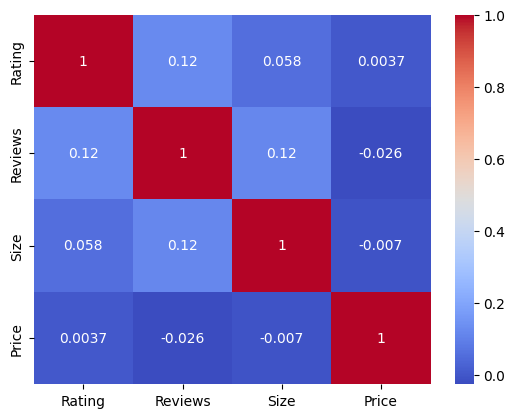

In [86]:
correlation = df[['Rating', 'Reviews', 'Size', 'Price']].corr()
sns.heatmap(correlation, annot=True, cmap="coolwarm")
plt.show()

## 1.	How many apps exist for each type (free/paid) across different content ratings?

In [87]:
df.groupby(['Type', 'Content Rating']).size()

Type  Content Rating 
Free  Adults only 18+       3
      Everyone           6764
      Everyone 10+        336
      Mature 17+          429
      Teen                995
      Unrated               1
Paid  Everyone            538
      Everyone 10+         32
      Mature 17+           16
      Teen                 40
dtype: int64

## 1.	How many apps are compatible with Android version 4.x?

In [88]:
df[df['Min Android Version'].str.startswith('4')].shape[0]


5721

# Save the cleaned version of the data

In [89]:
df.to_csv("cleaned_googleplaystore.csv", index=False)
